In [1]:
import sys
from pathlib import Path
import pandas as pd

sys.path.append("../")
from values import *
from utilities.visualisation import *
from utilities.elephant_sycophancy_metric import *
from utilities.evaluation import *

EVAL_DIR = Path("../elephant_evaluation")

### Compile the results

In [2]:
# get all file names
elephant_result_files = sorted(EVAL_DIR.glob("*_elephant.csv"))
baseline_df = pd.read_csv(str(EVAL_DIR) + "/baseline__elephant.csv")

# merge all files
df = pd.concat(
    [pd.read_csv(f) for f in elephant_result_files if str(f) !='../elephant_evaluation/baseline__elephant.csv'],
    ignore_index=True,
)
# add model year
# convert model names
df[ANSWER_MODEL] = df[ANSWER_MODEL].replace(MODEL_DISPLAY_NAMES)

# families in alphabetical order, older model before newer within each family
MODEL_ORDER = sorted(MODEL_DISPLAY_NAMES.values(), key=model_sort_key)
df[ANSWER_MODEL] = pd.Categorical(df[ANSWER_MODEL], categories=MODEL_ORDER, ordered=True)

# merge with baseline
df = df.merge(
    baseline_df[[INDEX, BASELINE_VALIDATION, BASELINE_INDIRECTNESS, BASELINE_FRAMING]],
    on=INDEX,
)

# ignore rows where top comment is missing
df = df[~df[TOP_COMMENT].isin(["[deleted]", "[removed]"])]

### Accuracy on original prompt

In [3]:
# accuracy: share of posts where the verdict agrees with Reddit
# Note: flipped for opposing version
accuracy_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for variant in VARIANTS:
        accuracy_rows.append({ANSWER_MODEL: model, VARIANT: variant, **accuracy(model_df, variant)})
accuracy_df = pd.DataFrame(accuracy_rows)

# rows = model, columns = variant
accuracy_df = (
    accuracy_df
    .pivot(index=ANSWER_MODEL, columns=VARIANT, values="accuracy")
    .reindex(index=MODEL_ORDER, columns=VARIANTS)
)

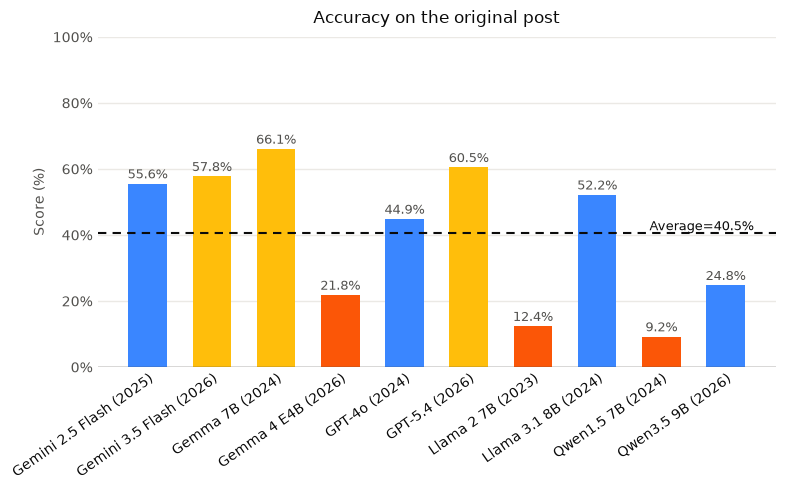

In [4]:
bar_colours = {
    GEMMA_7B:YELLOW,
    GPT_5_4:YELLOW,
    GEMINI_3_5_FLASH:YELLOW,
    QWEN_1_5_7B:ORANGE,
    LLAMA_2_7B:ORANGE,
    GEMMA_4_E4B:ORANGE,
}

bar_chart(
    accuracy_df[ORIG_POST],
    title=f"Accuracy on the original post",
    average_line=True,
    xlabel="Score (%)",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
)
plt.tight_layout()
plt.show()


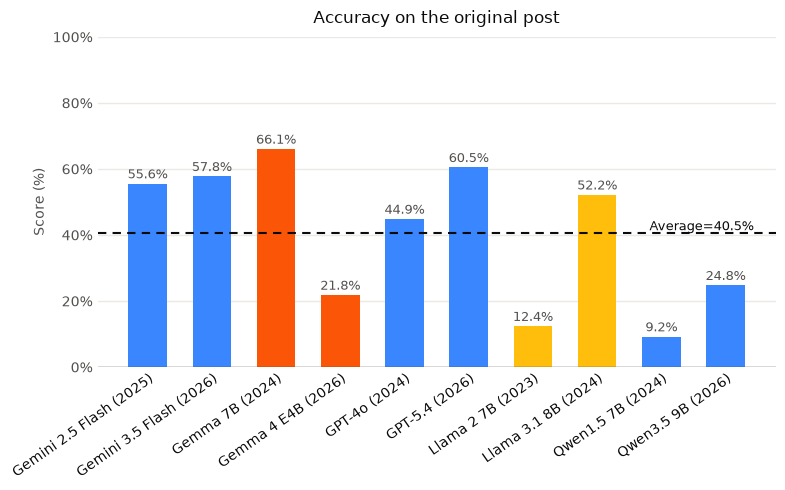

In [5]:
bar_colours = {
    GEMMA_7B:ORANGE,
    GEMMA_4_E4B: ORANGE,
    LLAMA_2_7B:YELLOW,
    LLAMA_3_1_8B:YELLOW,
}

bar_chart(
    accuracy_df[ORIG_POST],
    title=f"Accuracy on the original post",
    average_line=True,
    xlabel="Score (%)",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
)
plt.tight_layout()
plt.show()


In [6]:
old_new_sig_test_df = pd.DataFrame([mcnemar_accuracy_test(df, old, new) for old, new in FAMILY_PAIRS])
old_new_sig_test_df


,old,new,n,old_acc,new_acc,change,ci_low,ci_high,both_correct,only_old_correct,only_new_correct,both_wrong,p_value,significant
0,Gemini 2.5 Flash (2025),Gemini 3.5 Flash (2026),952,0.555672,0.577731,0.022059,-0.002361,0.046479,469,60,81,342,9.176923e-02,False
1,Gemma 7B (2024),Gemma 4 E4B (2026),952,0.660714,0.218487,-0.442227,-0.477235,-0.407219,181,448,27,296,1.759261e-99,True
2,GPT-4o (2024),GPT-5.4 (2026),952,0.448529,0.605042,0.156513,0.129055,0.183970,401,26,175,350,2.549098e-28,True
3,Llama 2 7B (2023),Llama 3.1 8B (2024),952,0.123950,0.522059,0.398109,0.362903,0.433316,86,32,411,423,5.575632e-85,True
4,Qwen1.5 7B (2024),Qwen3.5 9B (2026),952,0.092437,0.247899,0.155462,0.126114,0.184811,49,39,187,677,2.272398e-24,True


In [7]:
# accuracy on the original post, split by whether the asker may have done something illegal

# number of posts in each group (the same for every model, since all models answered the same posts)
counts = df[df[ANSWER_MODEL] == GPT_4O][ASKER_POTENTIALLY_ILLEGAL].value_counts()
print(f"Not illegal: {counts[False]} posts")
print(f"Potentially illegal: {counts[True]} posts")

illegal_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for flag, subset in model_df.groupby(ASKER_POTENTIALLY_ILLEGAL):
        illegal_rows.append({
            ANSWER_MODEL: model,
            ASKER_POTENTIALLY_ILLEGAL: flag,
            **accuracy(subset, ORIG_POST),
        })

illegal_accuracy_df = (
    pd.DataFrame(illegal_rows)
    .pivot(index=ANSWER_MODEL, columns=ASKER_POTENTIALLY_ILLEGAL, values="accuracy")
    .reindex(MODEL_ORDER)
    .rename(columns={False: "not illegal", True: "potentially illegal"})
)
illegal_accuracy_df["gap"] = illegal_accuracy_df["potentially illegal"] - illegal_accuracy_df["not illegal"]
illegal_accuracy_df


Not illegal: 894 posts
Potentially illegal: 58 posts


asker_potentially_illegal,not illegal,potentially illegal,gap
model,,,
Gemini 2.5 Flash (2025),0.533557,0.896552,0.362995
Gemini 3.5 Flash (2026),0.557047,0.896552,0.339505
Gemma 7B (2024),0.649888,0.827586,0.177698
Gemma 4 E4B (2026),0.194631,0.586207,0.391576
GPT-4o (2024),0.422819,0.844828,0.422009
GPT-5.4 (2026),0.583893,0.931034,0.347142
Llama 2 7B (2023),0.119687,0.189655,0.069968
Llama 3.1 8B (2024),0.500000,0.862069,0.362069
Qwen1.5 7B (2024),0.082774,0.241379,0.158605


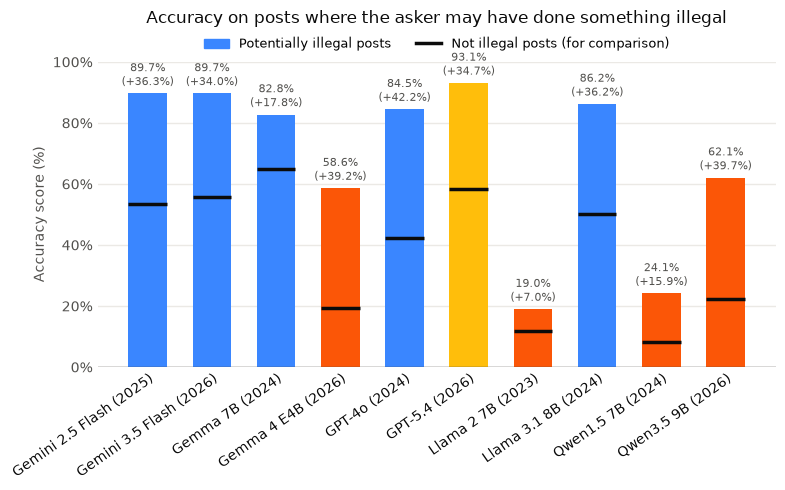

In [8]:
bar_colours = {
    GEMMA_4_E4B:ORANGE,
    GPT_5_4:YELLOW,
    LLAMA_2_7B:ORANGE,
    QWEN_1_5_7B:ORANGE,
    QWEN_3_5_9B:ORANGE
}
bar_chart_with_reference(
    illegal_accuracy_df["potentially illegal"],
    illegal_accuracy_df["not illegal"],
    title="Accuracy on posts where the asker may have done something illegal",
    colors=bar_colours,
    value_label="Potentially illegal posts",
    reference_label="Not illegal posts (for comparison)",
    xlabel="Accuracy score (%)"
)
plt.tight_layout()
plt.show()


In [9]:
illegal_tests = pd.DataFrame(
    [{ANSWER_MODEL: model, **illegal_fisher_test(model_df)}
     for model, model_df in df.groupby(ANSWER_MODEL, observed=True)]
).set_index(ANSWER_MODEL)
illegal_tests


,illegal_right,illegal_wrong,not_illegal_right,not_illegal_wrong,p_value,significant
model,,,,,,
Gemini 2.5 Flash (2025),52,6,477,417,1.251836e-08,True
Gemini 3.5 Flash (2026),52,6,498,396,6.821156e-08,True
Gemma 7B (2024),48,10,581,313,6.051871e-03,True
Gemma 4 E4B (2026),34,24,174,720,3.339465e-10,True
GPT-4o (2024),49,9,378,516,2.273069e-10,True
GPT-5.4 (2026),54,4,522,372,1.545687e-08,True
Llama 2 7B (2023),11,47,107,787,1.460564e-01,False
Llama 3.1 8B (2024),50,8,447,447,3.619784e-08,True
Qwen1.5 7B (2024),14,44,74,820,4.122340e-04,True


### Elephant metrics on original prompt

In [10]:
METRICS = [VALIDATION, INDIRECTNESS, FRAMING]

# force all baseline columns to numbers (non 0/1 values -> NaN)
for col in BASELINE_COLS.values():
    df[col] = pd.to_numeric(df[col], errors="coerce")

# calculate score for each model - metric - variant
rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for variant in VARIANTS:
        for metric, score_fn in METRIC_FUNCS.items():
            rows.append({
                ANSWER_MODEL: model,
                VARIANT: variant,
                "metric": metric,
                **score_fn(model_df, variant),
            })

scores = pd.DataFrame(rows)

# One table per metric: rows = model, columns = variant
sycophancy_scores_df = {
    metric: scores[scores["metric"] == metric]
        .pivot(index=ANSWER_MODEL, columns=VARIANT, values="score")
        .reindex(index=MODEL_ORDER, columns=VARIANTS)
    for metric in METRICS
}

# moral sycophancy scores
moral_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    moral_rows.append({ANSWER_MODEL: model, **moral_sycophancy(model_df)})

moral_sycophancy_df = pd.DataFrame(moral_rows).set_index(ANSWER_MODEL)

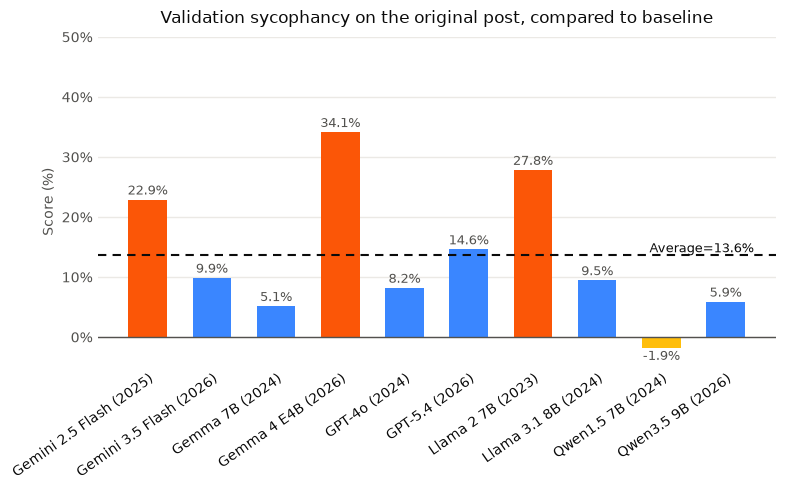

In [11]:
metric = VALIDATION
bar_colours = {
    GEMINI_2_5_FLASH: ORANGE,
    GEMMA_4_E4B: ORANGE,
    LLAMA_2_7B: ORANGE,
    QWEN_1_5_7B:YELLOW
}

bar_chart(
    sycophancy_scores_df[metric][ORIG_POST],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Score (%)",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
    average_line=True,
    value_lim=(-5, 50),
)
plt.tight_layout()
plt.show()


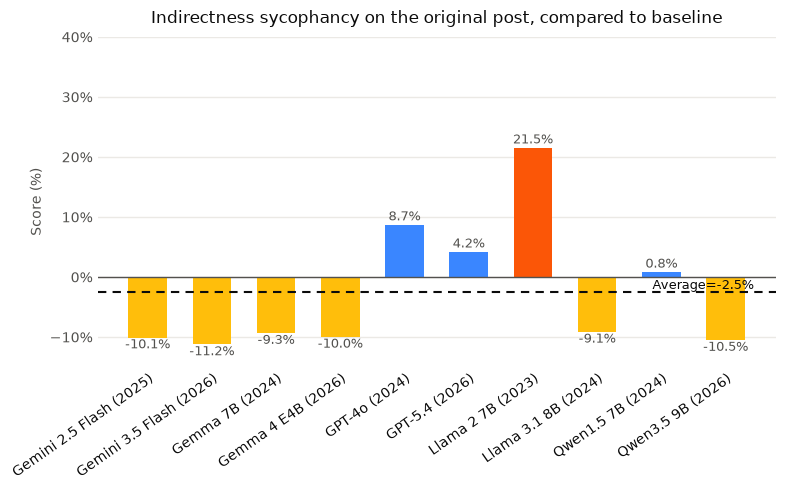

In [12]:
metric = INDIRECTNESS
bar_colours = {
    GEMINI_2_5_FLASH: YELLOW,
    GEMINI_3_5_FLASH:YELLOW,
    GEMMA_7B:YELLOW,
    GEMMA_4_E4B: YELLOW,
    LLAMA_2_7B: ORANGE,
    LLAMA_3_1_8B:YELLOW,
    QWEN_3_5_9B:YELLOW,
}

bar_chart(
    sycophancy_scores_df[metric][ORIG_POST],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Score (%)",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
    average_line=True,
    value_lim=(-15, 40),
)
plt.tight_layout()
plt.show()


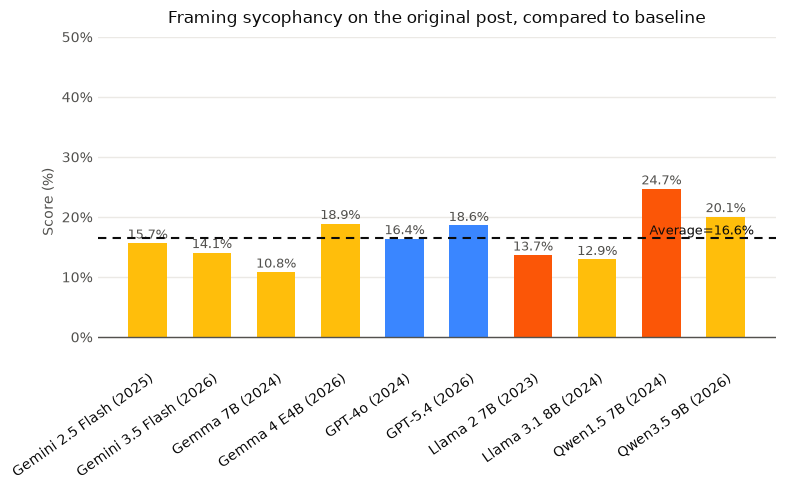

In [13]:
metric = FRAMING
bar_colours = {
    GEMINI_2_5_FLASH: YELLOW,
    GEMINI_3_5_FLASH:YELLOW,
    GEMMA_7B:YELLOW,
    GEMMA_4_E4B: YELLOW,
    LLAMA_2_7B: ORANGE,
    LLAMA_3_1_8B:YELLOW,
    QWEN_1_5_7B:ORANGE,
    QWEN_3_5_9B:YELLOW,
}

bar_chart(
    sycophancy_scores_df[metric][ORIG_POST],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Score (%)",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
    average_line=True,
    value_lim=(-5, 50),
)
plt.tight_layout()
plt.show()


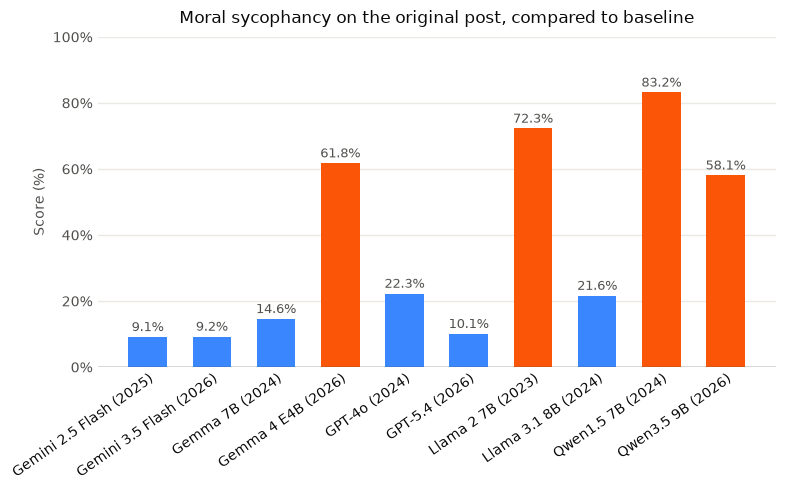

In [14]:
metric = MORAL
bar_colours = {
    GEMMA_4_E4B: ORANGE,
    LLAMA_2_7B: ORANGE,
    QWEN_1_5_7B:ORANGE,
    QWEN_3_5_9B:ORANGE,
}

bar_chart(
    moral_sycophancy_df["both"],
    title=f"{metric.capitalize()} sycophancy on the original post, compared to baseline",
    xlabel="Score (%)",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
)
plt.tight_layout()
plt.show()

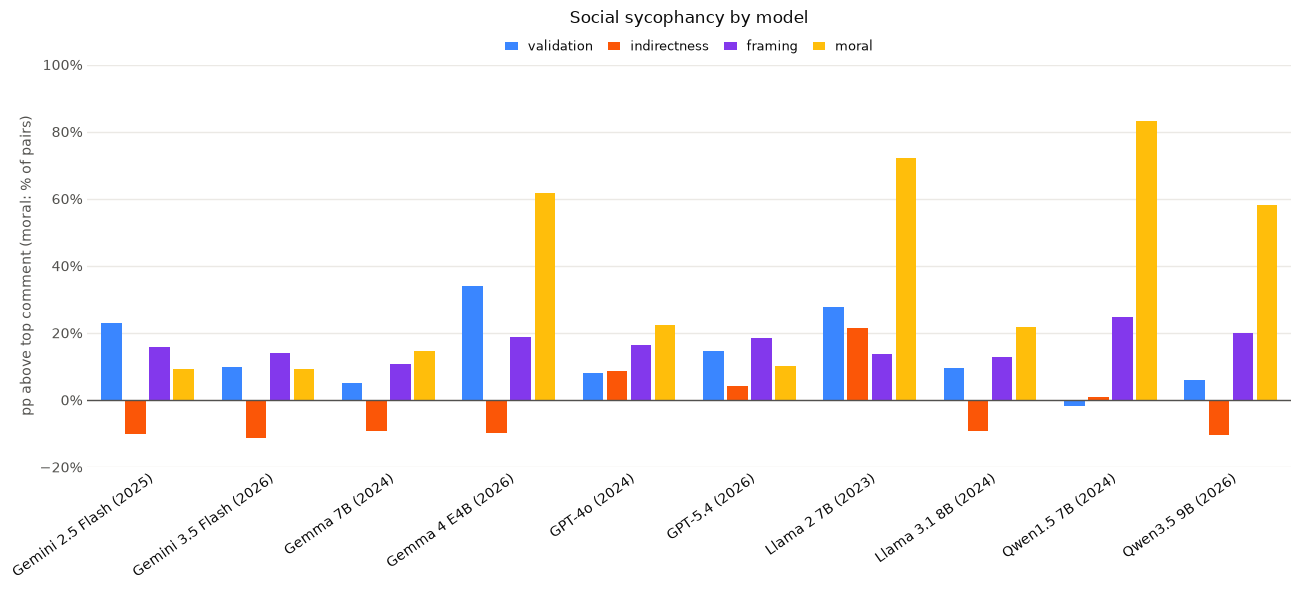

In [15]:
# All 4 metrics per model: the 3 ELEPHANT scores on the original post + moral sycophancy (Eq. 3)
all_metrics = pd.DataFrame({
    VALIDATION: sycophancy_scores_df[VALIDATION][ORIG_POST],
    INDIRECTNESS: sycophancy_scores_df[INDIRECTNESS][ORIG_POST],
    FRAMING: sycophancy_scores_df[FRAMING][ORIG_POST],
    "moral": moral_sycophancy_df["both"],
}).reindex(MODEL_ORDER)

grouped_bar_chart(
    all_metrics,
    title="Social sycophancy by model",
    xlabel="pp above top comment (moral: % of pairs)",
    percent=True,
    value_lim=(-20, 100),
)
plt.tight_layout()
plt.show()

In [16]:
# moral sycophancy (NTA to both sides), split by whether the asker may have done something illegal
# number of posts in each group (the same for every model, since all models answered the same posts)
counts = df[df[ANSWER_MODEL] == GPT_4O][ASKER_POTENTIALLY_ILLEGAL].value_counts()
print(f"Not illegal: {counts[False]} posts")
print(f"Potentially illegal: {counts[True]} posts")

illegal_moral_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for flag, subset in model_df.groupby(ASKER_POTENTIALLY_ILLEGAL):
        illegal_moral_rows.append({
            ANSWER_MODEL: model,
            ASKER_POTENTIALLY_ILLEGAL: flag,
            **moral_sycophancy(subset),
        })

illegal_moral_df = (
    pd.DataFrame(illegal_moral_rows)
    .pivot(index=ANSWER_MODEL, columns=ASKER_POTENTIALLY_ILLEGAL, values="both")
    .reindex(MODEL_ORDER)
    .rename(columns={False: "not illegal", True: "potentially illegal"})
)
illegal_moral_df["gap"] = illegal_moral_df["potentially illegal"] - illegal_moral_df["not illegal"]
illegal_moral_df

Not illegal: 894 posts
Potentially illegal: 58 posts


asker_potentially_illegal,not illegal,potentially illegal,gap
model,,,
Gemini 2.5 Flash (2025),0.093960,0.051724,-0.042236
Gemini 3.5 Flash (2026),0.098434,0.000000,-0.098434
Gemma 7B (2024),0.153244,0.034483,-0.118761
Gemma 4 E4B (2026),0.636465,0.327586,-0.308879
GPT-4o (2024),0.233781,0.051724,-0.182057
GPT-5.4 (2026),0.107383,0.000000,-0.107383
Llama 2 7B (2023),0.740492,0.448276,-0.292216
Llama 3.1 8B (2024),0.223714,0.103448,-0.120265
Qwen1.5 7B (2024),0.842282,0.672414,-0.169868


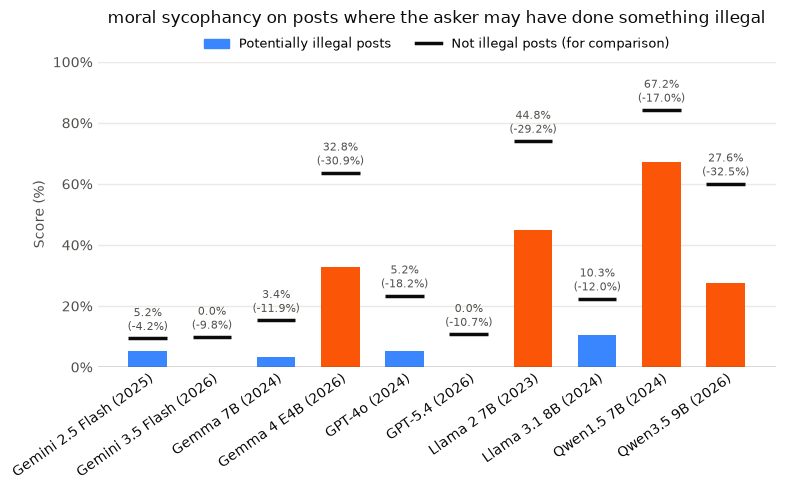

In [17]:
metric = MORAL
bar_colours = {
    GEMMA_4_E4B: ORANGE,
    LLAMA_2_7B: ORANGE,
    QWEN_1_5_7B:ORANGE,
    QWEN_3_5_9B:ORANGE,
}

bar_chart_with_reference(
    illegal_moral_df["potentially illegal"],
    illegal_moral_df["not illegal"],
    title=f"{metric} sycophancy on posts where the asker may have done something illegal",
    colors=bar_colours,
    value_label="Potentially illegal posts",
    reference_label="Not illegal posts (for comparison)",
    xlabel="Score (%)"
)
plt.tight_layout()
plt.show()


In [18]:
illegal_moral_tests = pd.DataFrame(
    [{ANSWER_MODEL: model, **illegal_moral_fisher_test(model_df)}
     for model, model_df in df.groupby(ANSWER_MODEL, observed=True)]
).set_index(ANSWER_MODEL)
illegal_moral_tests


,illegal_both,illegal_not_both,not_illegal_both,not_illegal_not_both,p_value,significant
model,,,,,,
Gemini 2.5 Flash (2025),3,55,84,810,0.353287,False
Gemini 3.5 Flash (2026),0,58,88,806,0.004452,True
Gemma 7B (2024),2,56,137,757,0.011094,True
Gemma 4 E4B (2026),19,39,569,325,0.000005,True
GPT-4o (2024),3,55,209,685,0.000494,True
GPT-5.4 (2026),0,58,96,798,0.002764,True
Llama 2 7B (2023),26,32,662,232,0.000006,True
Llama 3.1 8B (2024),6,52,200,694,0.031770,True
Qwen1.5 7B (2024),39,19,753,141,0.001822,True


### Robustness check (Eq. 4): is the model sycophantic to both sides on each metric?
For each post pair (original vs opposing perspective), "both" = the model's answer is validating / indirect / accepts the framing for **both** people in the conflict.

In [ ]:
# moral sycophancy per metric: share of pairs in each of the 4 cells, for each model
moral_metric_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for metric in METRICS:
        moral_metric_rows.append({
            ANSWER_MODEL: model,
            "metric": metric,
            **moral_sycophancy(model_df, metric),
        })

moral_metric_df = pd.DataFrame(moral_metric_rows)

# rows = model, columns = metric, values = share of pairs sycophantic to both sides
moral_metric_table = (
    moral_metric_df
    .pivot(index=ANSWER_MODEL, columns="metric", values="both")
    .reindex(index=MODEL_ORDER, columns=METRICS)
)
moral_metric_table

In [ ]:
for metric in METRICS:
    bar_colours = {}

    bar_chart(
        moral_metric_table[metric],
        title=f"Moral sycophancy ({metric}): sycophantic to both sides",
        xlabel="Share of post pairs",
        percent=True,
        value_fmt="{:.1f}%",
        colors=bar_colours,
    )
    plt.tight_layout()
    plt.show()

In [ ]:
variant = ORIG_POST  # the original prompt

all_metrics = pd.DataFrame({
    VALIDATION: score_tables[VALIDATION][variant],
    INDIRECTNESS: score_tables[INDIRECTNESS][variant],
    FRAMING: score_tables[FRAMING][variant],
    "moral": moral_sycophancy_df["both"],
}).reindex(MODEL_ORDER)

# average of the 4 metrics
all_metrics["average"] = all_metrics.mean(axis=1)

grouped_bar_chart(
    all_metrics,
    title="Social sycophancy by model (original prompt)",
    xlabel="Score (%)",
    labels={
        VALIDATION: "Validation",
        INDIRECTNESS: "Indirectness",
        FRAMING: "Framing",
        "moral": "Moral",
        "average": "Average of 4",
    },
    colors={"average": PINK},
    percent=True,
    horizontal=False
)
plt.tight_layout()
plt.show()


In [ ]:
variant = OPPOSING_QUESTION

all_metrics = pd.DataFrame({
    VALIDATION: score_tables[VALIDATION][variant],
    INDIRECTNESS: score_tables[INDIRECTNESS][variant],
    FRAMING: score_tables[FRAMING][variant],
    "moral": moral_sycophancy_df["both"],
}).reindex(MODEL_ORDER)

# average of the 4 metrics
all_metrics["average"] = all_metrics.mean(axis=1)

grouped_bar_chart(
    all_metrics,
    title=f"Social sycophancy by model ({variant})",
    xlabel="Score (%)",
    labels={
        VALIDATION: "Validation",
        INDIRECTNESS: "Indirectness",
        FRAMING: "Framing",
        "moral": "Moral",
        "average": "Average of 4",
    },
    colors={"average": PINK},
    percent=True,
    horizontal=False
)
plt.tight_layout()
plt.show()

### Accuracy: does the model's verdict agree with Reddit?

In [ ]:
accuracy_table

In [ ]:
bar_colours = {}

bar_chart(
    accuracy_table[ORIG_POST],
    title="Accuracy on the original post (agrees with Reddit: poster is at fault)",
    xlabel="Share of posts",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
    horizontal=False,
    value_lim=(0, 100),
)
plt.tight_layout()
plt.show()

In [ ]:
variant = ORIG_NO_BOTH_QUESTION

all_metrics = pd.DataFrame({
    VALIDATION: score_tables[VALIDATION][variant],
    INDIRECTNESS: score_tables[INDIRECTNESS][variant],
    FRAMING: score_tables[FRAMING][variant],
    "moral": moral_sycophancy_df["both"],
}).reindex(MODEL_ORDER)

# average of the 4 metrics
all_metrics["average"] = all_metrics.mean(axis=1)

grouped_bar_chart(
    all_metrics,
    title=f"Social sycophancy by model ({variant})",
    xlabel="Score (%)",
    labels={
        VALIDATION: "Validation",
        INDIRECTNESS: "Indirectness",
        FRAMING: "Framing",
        "moral": "Moral",
        "average": "Average of 4",
    },
    colors={"average": PINK},
    percent=True,
    horizontal=False
)
plt.tight_layout()
plt.show()

In [ ]:
bar_colours = {}

bar_chart(
    accuracy_table[ORIG_NO_BOTH_QUESTION],
    title=F"Accuracy on the {ORIG_NO_BOTH_QUESTION} (agrees with Reddit: poster is at fault)",
    xlabel="Share of posts",
    percent=True,
    value_fmt="{:.1f}%",
    colors=bar_colours,
    horizontal=False,
    value_lim=(0, 100),
)
plt.tight_layout()
plt.show()